In [ ]:
%pip install langgraph langchain-google-genai langchain-core langchain-community langchain-tavily pydantic python-dotenv requests
%pip install langchain-community langchain-tavily pydantic python-dotenv
%pip install requests
%pip install ipywidgets

In [1]:
from __future__ import annotations

import operator
import os
import re
import requests
import base64
from datetime import date, timedelta
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Annotated

from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.tools.tavily_search import TavilySearchResults
import importlib
import checkpointer
from langgraph.types import interrupt, Command
from wordpress_mcp import (
    WordPressMCPClient,
    auth_callback_widget,
    callback_status
)

C:\Users\inspiron 5430\AppData\Local\Temp\ipykernel_18592\2941828353.py:19: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
importlib.reload(checkpointer)
connection_pool, checkpointer_instance = (
    await checkpointer.initialize_checkpointer()
)

In [3]:
# -----------------------------
# 1) Schemas
# -----------------------------
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=6,
        description="3–6 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(..., description="Target word count for this section (120–550).")

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)


class ImageSpec(BaseModel):
    placeholder: str = Field(..., description="e.g. [[IMAGE_1]]")
    filename: str = Field(..., description="Save under images/, e.g. qkv_flow.png")
    alt: str
    caption: str
    prompt: str = Field(..., description="Prompt to send to the image model.")
    size: Literal["1024x1024", "1024x1536", "1536x1024"] = "1024x1024"
    quality: Literal["low", "medium", "high"] = "medium"


class GlobalImagePlan(BaseModel):
    md_with_placeholders: str
    images: List[ImageSpec] = Field(default_factory=list)


In [4]:
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)

    # reducer/image
    merged_md: str
    md_with_placeholders: str
    image_specs: List[dict]
    review_status: str
    review_feedback: str
    revision_count: int
    revision_history: list
    
    final: str
    
    # New WordPress fields
    wordpress_post_id: Optional[int]
    wordpress_post_url: Optional[str]
    wordpress_status: Optional[str]


# -----------------------------
# 2) LLM
# -----------------------------
llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    google_api_key=os.getenv("GOOGLE_API_KEY"),
    temperature=0
)


In [5]:
# -----------------------------
# 3) Router (decide upfront)
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    
    topic = state["topic"]
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    )

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }

def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"


In [6]:
# -----------------------------
# 4) Research (Tavily) 
# -----------------------------
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:

    # take the first 10 queries from state
    queries = (state.get("queries", []) or [])
    max_results = 6

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{raw_results}"),
        ]
    )

    # Deduplicate by URL
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e

    return {"evidence": list(dedup.values())}


In [7]:
# -----------------------------
# 5) Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5–9 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–6 bullets that are concrete, specific, and non-overlapping
  3) target word count (120–550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
  * minimal code sketch / MWE (set requires_code=True for that section)
  * edge cases / failure modes
  * performance/cost considerations
  * security/privacy considerations (if relevant)
  * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
  - Use evidence for up-to-date examples (models/tools/releases) in bullets.
  - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Mode open_book:
  - Set blog_kind = "news_roundup".
  - Every section is about summarizing events + implications.
  - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
  - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources"
    and includes only what can be supported.

Output must strictly match the Plan schema.
"""

def orchestrator_node(state: State) -> dict:
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:16]}"
                )
            ),
        ]
    )

    return {"plan": plan}

# -----------------------------
# 6) Fanout
# -----------------------------
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]



In [8]:
# -----------------------------
# 7) Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )
    response = llm.invoke(
    [
        SystemMessage(content=WORKER_SYSTEM),
        HumanMessage(
            content=(
                f"Blog title: {plan.blog_title}\n"
                f"Audience: {plan.audience}\n"
                f"Tone: {plan.tone}\n"
                f"Blog kind: {plan.blog_kind}\n"
                f"Constraints: {plan.constraints}\n"
                f"Topic: {topic}\n"
                f"Mode: {mode}\n\n"
                f"Section title: {task.title}\n"
                f"Goal: {task.goal}\n"
                f"Target words: {task.target_words}\n"
                f"Tags: {task.tags}\n"
                f"requires_research: {task.requires_research}\n"
                f"requires_citations: {task.requires_citations}\n"
                f"requires_code: {task.requires_code}\n"
                f"Bullets:{bullets_text}\n\n"
                f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
            )
        ),
    ]
)

    # Extract generated text from Gemini response
    content = response.content

    if isinstance(content, str):
        section_md = content.strip()
    else:
        section_md = "\n".join(
            block["text"]
            for block in content
            if isinstance(block, dict) and block.get("type") == "text"
        ).strip()

    return {"sections": [(task.id, section_md)]}
        

    

In [9]:
# ============================================================
# 8) ReducerWithImages (subgraph)
#    merge_content -> decide_images -> generate_and_place_images
# ============================================================
def merge_content(state: State) -> dict:

    plan = state["plan"]

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    merged_md = f"# {plan.blog_title}\n\n{body}\n"
    return {"merged_md": merged_md}


DECIDE_IMAGES_SYSTEM = """You are an expert technical editor.
Decide if images/diagrams are needed for THIS blog.

Rules:
- Max 3 images total.
- Each image must materially improve understanding (diagram/flow/table-like visual).
- Insert placeholders exactly: [[IMAGE_1]], [[IMAGE_2]], [[IMAGE_3]].
- If no images needed: md_with_placeholders must equal input and images=[].
- Avoid decorative images; prefer technical diagrams with short labels.
Return strictly GlobalImagePlan.
"""

def decide_images(state: State) -> dict:
    
    planner = llm.with_structured_output(GlobalImagePlan)
    merged_md = state["merged_md"]
    plan = state["plan"]
    assert plan is not None

    image_plan = planner.invoke(
        [
            SystemMessage(content=DECIDE_IMAGES_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Topic: {state['topic']}\n\n"
                    "Insert placeholders + propose image prompts.\n\n"
                    f"{merged_md}"
                )
            ),
        ]
    )

    return {
        "md_with_placeholders": image_plan.md_with_placeholders,
        "image_specs": [img.model_dump() for img in image_plan.images],
    }


def _cloudflare_generate_image_bytes(prompt: str) -> bytes:

    account_id = os.getenv("CLOUDFLARE_ACCOUNT_ID")
    api_token = os.getenv("CLOUDFLARE_API_TOKEN")

    if not account_id or not api_token:
        raise RuntimeError("Cloudflare credentials are missing.")

    url = (
        f"https://api.cloudflare.com/client/v4/accounts/"
        f"{account_id}/ai/run/@cf/black-forest-labs/flux-1-schnell"
    )

    headers = {
        "Authorization": f"Bearer {api_token}"
    }

    payload = {
        "prompt": prompt
    }

    response = requests.post(
        url,
        headers=headers,
        json=payload,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()

    image_base64 = data["result"]["image"]

    image_bytes = base64.b64decode(image_base64)

    return image_bytes


def generate_and_place_images(state: State) -> dict:

    plan = state["plan"]
    assert plan is not None

    md = state.get("md_with_placeholders") or state["merged_md"]
    image_specs = state.get("image_specs", []) or []

    if not image_specs:
        return {"final": md}

    images_dir = Path("images")
    images_dir.mkdir(exist_ok=True)

    for spec in image_specs:

        placeholder = spec["placeholder"]

        # Sanitize filename
        filename = (
            spec["filename"]
            .replace("\\", "")
            .replace("/", "")
        )

        out_path = images_dir / filename

        if not out_path.exists():
            try:
                img_bytes = _cloudflare_generate_image_bytes(
                    spec["prompt"]
                )
                out_path.write_bytes(img_bytes)

            except Exception as e:
                prompt_block = (
                    f"> **[IMAGE GENERATION FAILED]** "
                    f"{spec.get('caption', '')}\n>\n"
                    f"> **Alt:** {spec.get('alt', '')}\n>\n"
                    f"> **Error:** {e}\n"
                )

                md = md.replace(placeholder, prompt_block)
                continue

        # Images are in project/images
        # Markdown file is in project/outputs
        image_path = f"../images/{filename}"

        img_md = (
            f'<img src="{image_path}" '
            f'alt="{spec["alt"]}" '
            f'width="650"/>\n\n'
            f'*{spec["caption"]}*'
        )

        md = md.replace(placeholder, img_md)

    return {"final": md}



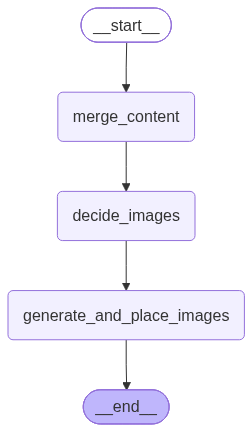

In [10]:
# build reducer subgraph
reducer_graph = StateGraph(State)
reducer_graph.add_node("merge_content", merge_content)
reducer_graph.add_node("decide_images", decide_images)
reducer_graph.add_node("generate_and_place_images", generate_and_place_images)
reducer_graph.add_edge(START, "merge_content")
reducer_graph.add_edge("merge_content", "decide_images")
reducer_graph.add_edge("decide_images", "generate_and_place_images")
reducer_graph.add_edge("generate_and_place_images", END)
reducer_subgraph = reducer_graph.compile()

reducer_subgraph


In [11]:
def reducer_node(state: State) -> dict:

    result = reducer_subgraph.invoke(state)

    return {
        "merged_md": result["merged_md"],
        "md_with_placeholders": result["md_with_placeholders"],
        "image_specs": result["image_specs"],
        "final": result["final"],
    }

In [12]:
# ============================================================
# 9) Human Review Node
# ============================================================
from langgraph.types import interrupt

def human_review(state: State) -> dict:
    review = interrupt({
        "message": "Review the generated blog",
        "blog": state["final"],
        "revision_count": state["revision_count"]
    })

    return {
        "review_status": review["action"],
        "review_feedback": review.get("feedback", ""),
        "final": review.get("edited_blog", state["final"])
    }

In [13]:
MAX_REVISIONS = 5

def route_after_review(state: State) -> str:
    status = state["review_status"]

    if status == "approved":
        return "wordpress_draft_node"

    elif status == "revision_requested":
        if state["revision_count"] >= MAX_REVISIONS:
            return "manual_intervention"

        return "revision"

    elif status == "manually_edited":
        return "human_review"

    else:
        raise ValueError(f"Unknown review status: {status}")

In [14]:
def revision_node(state: State) -> dict:

    existing_blog = state["final"]

    # Normalize blog content into a string
    if isinstance(existing_blog, list):
        existing_blog = "\n".join(
            item.get("text", "")
            for item in existing_blog
            if isinstance(item, dict)
        )

    prompt = f"""
    You are an expert blog editor.

    Revise the existing blog based on the human feedback.

    EXISTING BLOG:
    {existing_blog}

    HUMAN FEEDBACK:
    {state["review_feedback"]}

    Instructions:
    - Preserve the original topic and core meaning.
    - Address all the feedback.
    - Improve clarity, structure, and readability.
    - Return only the revised Markdown blog.
    """

    response = llm.invoke(prompt)

    return {
        "final": response.content,
        "revision_count": state["revision_count"] + 1
    }

In [15]:
def manual_intervention_node(state: State) -> dict:
    return {
        "review_status": "manual_intervention_required"
    }

In [16]:

async def wordpress_draft_node(state: State) -> dict:

    # 1. Only create a draft after content approval
    if state.get("review_status") != "approved":
        raise ValueError("Blog must be approved before creating a WordPress draft.")

    # 2. Prevent duplicate drafts when the graph resumes
    existing_post_id = state.get("wordpress_post_id")

    if existing_post_id:
        print(f"WordPress draft already exists: {existing_post_id}")

        return {
            "wordpress_post_id": existing_post_id,
            "wordpress_post_url": state.get("wordpress_post_url"),
            "wordpress_status": state.get("wordpress_status")
        }

    # 3. Get the blog content
    content = state.get("final")

    if not content:
        raise ValueError("Final blog content is missing.")

    # Use the topic as the initial post title
    title = state["topic"]

    # 4. Connect and create the WordPress draft
    client = WordPressMCPClient()

    try:
        await client.connect()

        post = await client.create_post(
            title=title,
            content=content,
            confirmed=True
        )

        # 5. Extract the returned WordPress post details
        post_id = post["id"]
        post_url = post["link"]
        post_status = post["status"]

        print("\nWordPress draft created successfully!")
        print(f"Post ID: {post_id}")
        print(f"Title: {title}")
        print(f"Status: {post_status}")
        print(f"URL: {post_url}")

        return {
            "wordpress_post_id": post_id,
            "wordpress_post_url": post_url,
            "wordpress_status": post_status
        }

    finally:
        await client.close()


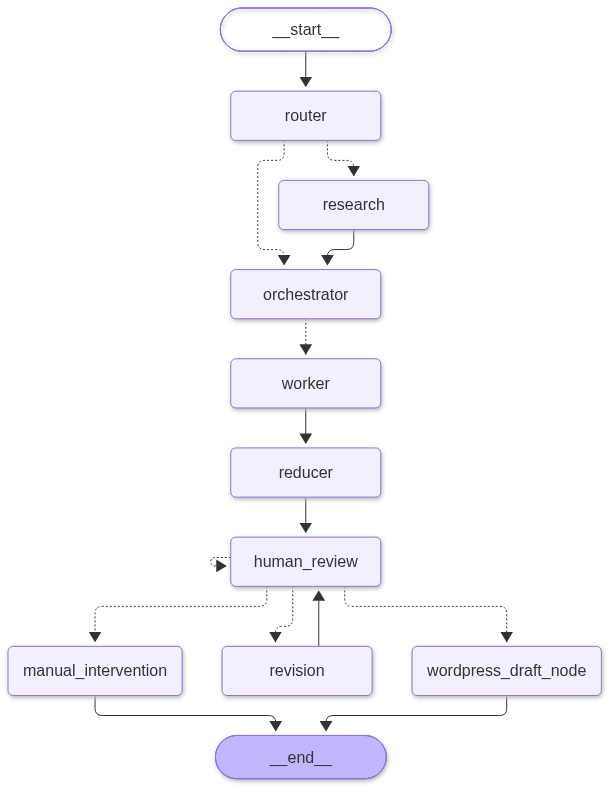

In [17]:
# -----------------------------
# 9) Build main graph
# -----------------------------
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_node)
g.add_node("human_review", human_review)
g.add_node("revision", revision_node)
g.add_node("wordpress_draft_node", wordpress_draft_node)
g.add_node("manual_intervention", manual_intervention_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", "human_review")
g.add_conditional_edges(
    "human_review",
    route_after_review,
    {
        "wordpress_draft_node": "wordpress_draft_node",
        "revision": "revision",
        "human_review" : "human_review",
        "manual_intervention": "manual_intervention"
    }
)
g.add_edge("revision", "human_review")
g.add_edge("manual_intervention", END)
g.add_edge("wordpress_draft_node", END)

app = g.compile(
    checkpointer=checkpointer_instance
)
app


In [18]:
import uuid
import re
async def run(topic: str, as_of: Optional[str] = None):
    if as_of is None:
        as_of = date.today().isoformat()

    config = {
        "configurable": {
            "thread_id": str(uuid.uuid4())
        }
    }
    Path("last_thread_id.txt").write_text(
        config["configurable"]["thread_id"],
        encoding="utf-8"
    )

    out = await app.ainvoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "as_of": as_of,
            "recency_days": 7,
            "sections": [],
            "merged_md": "",
            "md_with_placeholders": "",
            "image_specs": [],
            "review_status": "",
            "review_feedback": "",
            "revision_count": 0,
            "revision_history": [],
            "final": "",  
            "wordpress_post_id": None,
            "wordpress_post_url": None,
            "wordpress_status": None,
        },
        config=config
    )

    # Check whether graph paused for human review
    if out.get("__interrupt__"):
        review_data = out["__interrupt__"][0].value

        print("Human review required!")
        print(review_data["message"])

        from IPython.display import display, Markdown
        display(Markdown(review_data["blog"]))

    return {
        "output": out,
        "thread_id": config["configurable"]["thread_id"],
        "config": config
    }

In [19]:
result = await run("How RAG works")

Human review required!
Review the generated blog


# Demystifying RAG: How Retrieval-Augmented Generation Works

## The Core Problem: Why LLMs Need RAG

Large Language Models (LLMs) are powerful, but they are fundamentally static artifacts. Their intelligence is frozen at the moment their training concludes, a point known as the knowledge cutoff date. Because these models cannot natively access information published after this date, they are inherently blind to real-time events, evolving technical documentation, and shifting market conditions.

<img src="../images/rag_overview.png" alt="High-level RAG architecture diagram" width="650"/>

*The RAG architecture: A user query triggers a retrieval from a vector database, which is then combined with the query to provide context to the LLM.*

When an LLM is prompted to discuss topics outside its training distribution or internal knowledge base, it often resorts to "hallucinations." This phenomenon occurs when the model generates plausible-sounding but factually incorrect information to satisfy the probabilistic nature of its next-token prediction. For software engineers, this is particularly dangerous when dealing with proprietary codebases or private enterprise data, as the model lacks the context required to provide accurate, domain-specific answers.

To address this, developers often consider fine-tuning. However, fine-tuning is a resource-intensive process that updates the model’s internal weights to adapt its style or behavior. It is not an efficient mechanism for injecting dynamic, frequently changing data. Fine-tuning is best suited for behavioral alignment, whereas Retrieval-Augmented Generation (RAG) is the superior strategy for knowledge injection.

RAG functions as a bridge between static model weights and dynamic, external data. Instead of relying on the model’s internal memory, RAG architecture intercepts a user query, retrieves relevant context from an external vector database or document store, and injects that context into the prompt. This allows the model to ground its responses in verifiable, up-to-date information without requiring constant retraining or expensive parameter updates.

## Data Ingestion and Vectorization

The foundation of any Retrieval-Augmented Generation (RAG) system lies in transforming unstructured data into a machine-readable format. This process begins with **chunking**, where raw documents are segmented into smaller, semantically coherent pieces. Because Large Language Models (LLMs) have finite context windows and retrieval accuracy degrades with excessive noise, chunking ensures that each segment contains enough context to be meaningful without overwhelming the model. Common strategies include fixed-size sliding windows or recursive character splitting, which attempts to keep paragraphs or sentences intact.

Once chunked, these segments are passed to an **embedding model**. This model maps text into high-dimensional vector space, where the numerical distance between vectors represents semantic similarity. By converting text into dense vector representations, the system can perform mathematical operations to identify relevant information rather than relying on brittle keyword matching.

<img src="../images/embedding_process.png" alt="Data ingestion and vectorization flow" width="650"/>

*The ingestion pipeline: Raw text is chunked, passed through an embedding model, and stored as vectors in a database.*

```python
from sentence_transformers import SentenceTransformer

# Initialize the embedding model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Convert text chunks into high-dimensional vectors
chunks = ["RAG improves LLM accuracy.", "Vector databases store embeddings."]
embeddings = model.encode(chunks)

print(f"Vector dimension: {len(embeddings[0])}")
```

After vectorization, these embeddings are indexed in a **vector database**. Unlike traditional relational databases, vector stores are optimized for Approximate Nearest Neighbor (ANN) searches, allowing the system to query millions of vectors in milliseconds. The database stores the vector alongside the original text chunk, enabling the system to retrieve the raw content once the most relevant vectors are identified.

Finally, **metadata tagging** is critical for production-grade retrieval. During ingestion, you should attach attributes—such as document source, creation date, or security clearance levels—to each vector. During the retrieval phase, these tags allow for pre-filtering or post-filtering of results. For example, if a user queries for "company policy," the system can use metadata to restrict the search scope to documents tagged with the user's specific department. This combination of semantic vector search and structured metadata filtering ensures that the retrieved context is both relevant and contextually appropriate for the final generation step.

## The Retrieval Mechanism

The retrieval mechanism serves as the bridge between a user’s natural language query and the vast repository of unstructured data stored in your vector database. To ensure semantic alignment, the system must first transform the user's input into a high-dimensional vector representation. This process requires using the exact same embedding model—the same architecture, weights, and tokenizer—that was used to index the original knowledge base. By mapping the query into the same vector space as the stored documents, the system enables mathematical comparison between the intent of the user and the content of the data.

Once the query is vectorized, the system performs a similarity search to identify the most relevant data points. This is typically achieved through distance metrics:

*   **Cosine Similarity:** Measures the cosine of the angle between two vectors, focusing on the orientation rather than the magnitude. It is the standard for text embeddings where the direction of the vector captures semantic meaning.
*   **Euclidean Distance (L2):** Measures the straight-line distance between two points in space. While intuitive, it is often more sensitive to vector magnitude variations than cosine similarity.

In production environments, the choice of search algorithm involves a critical trade-off between precision and latency. An **exact search** (k-Nearest Neighbors) compares the query vector against every single vector in the database. While this guarantees the most accurate results, it becomes computationally prohibitive as the dataset scales to millions or billions of vectors. To solve this, engineers utilize **Approximate Nearest Neighbor (ANN)** algorithms, such as HNSW (Hierarchical Navigable Small World) or IVF (Inverted File Index). ANN sacrifices a marginal degree of accuracy for significant gains in search speed, allowing the system to return results in milliseconds by traversing a graph or partitioning the vector space rather than performing a brute-force scan.

Finally, the system employs a **top-k retrieval** strategy to filter the results. The "k" parameter defines the number of relevant document chunks to be retrieved and passed to the Large Language Model (LLM). This step is essential for managing the LLM’s context window. By limiting the retrieved information to the most pertinent "k" chunks, you prevent the model from being overwhelmed by noise, reduce token consumption costs, and mitigate the risk of "lost in the middle" phenomena, where models struggle to process information buried in excessively long prompts. Balancing the value of "k" is a core architectural decision that directly impacts the quality and relevance of the final generated response.

## Augmentation and Generation

Once the retrieval system identifies relevant chunks, the final phase involves synthesizing this information into a coherent response. This process relies on a structured prompt template that acts as the interface between your retrieved data and the Large Language Model (LLM).

### Constructing the Prompt Template
The prompt template is the blueprint for the LLM’s behavior. It typically includes three distinct sections:
1. **System Instructions:** Defines the persona and constraints (e.g., "You are a technical assistant. Answer only using the provided context.").
2. **Retrieved Context:** The raw text chunks injected into the prompt.
3. **User Query:** The original question posed by the user.

<img src="../images/prompt_construction.png" alt="Prompt template structure" width="650"/>

*The prompt template structure: Combining system instructions, retrieved context, and user query into a single input for the LLM.*

```python
prompt = f"""
System: Use the following context to answer the user's question. 
If the answer is not in the context, state that you do not know.

Context:
{retrieved_chunks}

User Question:
{user_query}
"""
```

### Grounding and Attribution
The LLM uses the context as a "grounding" mechanism, effectively constraining its knowledge base to the provided text. By forcing the model to reference the context, you significantly reduce hallucinations. To ensure transparency, the system should require the model to cite specific sources. You can achieve this by appending metadata (such as document IDs or URLs) to each chunk and instructing the model to append these identifiers to its claims.

### Handling Irrelevant Context
A critical architectural challenge is managing scenarios where the retrieval step returns no relevant information. If the similarity scores of retrieved chunks fall below a predefined threshold, the system should bypass the generation step entirely. Instead, the application should return a fallback response, such as "I couldn't find relevant information in the documentation," rather than allowing the LLM to rely on its internal, potentially outdated training data. 

By strictly enforcing these boundaries, you transform a generic LLM into a specialized, verifiable knowledge engine that remains tethered to your organization's proprietary data.

## Performance and Observability Considerations

Optimizing a Retrieval-Augmented Generation (RAG) pipeline requires a granular understanding of where time and capital are consumed. Performance bottlenecks typically emerge at the intersection of embedding generation and vector similarity search.

Embedding generation is often the primary latency driver for ingestion and real-time query processing. Depending on the model size and hardware acceleration, generating high-dimensional vectors for long documents can introduce significant overhead. Conversely, vector database lookups are generally optimized for speed, but latency scales non-linearly with the size of the index and the number of dimensions. To minimize latency, engineers should prioritize batching embedding requests and utilizing approximate nearest neighbor (ANN) algorithms, which trade marginal accuracy for sub-millisecond retrieval times.

Cost management is inextricably linked to the volume of retrieved context. Every token sent to the Large Language Model (LLM) incurs a cost. If a retrieval strategy pulls excessive chunks to ensure coverage, the resulting context window expansion can lead to exponential increases in API expenses. Implementing a strict "relevance threshold" or a reranking step—where a smaller, more precise model filters the top-k results before the final generation—is a standard architectural pattern to balance cost and performance.

Observability in RAG requires tracking two distinct domains: retrieval quality and generation accuracy. 
*   **Retrieval Logging:** Capture the query, the retrieved document IDs, and the similarity scores. This allows you to calculate metrics like Precision@K and Recall@K to determine if the system is actually finding the right information.
*   **Generation Logging:** Store the prompt, the retrieved context, and the final output. By comparing the output against ground-truth datasets, you can measure faithfulness and answer relevance.

Even with robust monitoring, RAG systems are susceptible to specific failure modes. The "lost in the middle" phenomenon occurs when LLMs prioritize information at the beginning or end of a prompt, often ignoring critical data buried in the center of a large context window. Furthermore, irrelevant context retrieval—where the vector database returns semantically similar but factually useless chunks—can lead to hallucinations. To mitigate these, implement "context window management" by truncating irrelevant data and using "chain-of-thought" prompting to force the model to explicitly cite the retrieved evidence. By treating retrieval and generation as separate, observable stages, you can isolate whether a failure stems from a poor search index or an inability of the LLM to synthesize the provided information.

In [20]:
# from pathlib import Path

# # 1. Read the previously saved thread ID
# thread_id = Path("last_thread_id.txt").read_text(
#     encoding="utf-8"
# ).strip()

# # 2. Tell LangGraph which execution to retrieve
# config = {
#     "configurable": {
#         "thread_id": thread_id
#     }
# }

# # 3. Retrieve its saved state from PostgreSQL
# state = app.get_state(config)

# # 4. Access the previously generated blog
# existing_blog = state.values["final"]

# print(existing_blog)

In [21]:
def blog_to_text(blog):
    """Convert the blog returned by the interrupt into editable text."""

    if isinstance(blog, list):
        return "\n".join(
            item.get("text", "")
            for item in blog
            if isinstance(item, dict)
        )

    return blog or ""


def show_review_ui(interrupt_data):
    """Display the latest blog and restore the review buttons."""

    # Update the editor with the latest generated blog
    manual_editor.value = blog_to_text(interrupt_data["blog"])

    # Enable all review buttons
    approve_btn.disabled = False
    revision_btn.disabled = False
    edit_btn.disabled = False
    submit_feedback_btn.disabled = False
    submit_edit_btn.disabled = False
    # Display the three review options again
    review_area.children = (
        widgets.HBox([
            approve_btn,
            revision_btn,
            edit_btn
        ]),
    )

    print("Review interface displayed.")
    print("Revision count:", interrupt_data.get("revision_count"))

In [ ]:
import ipywidgets as widgets
from IPython.display import display
from langgraph.types import Command
import asyncio

# Review buttons
approve_btn = widgets.Button(description="Approve")
revision_btn = widgets.Button(description="Request revision")
edit_btn = widgets.Button(description="Edit manually")

# Feedback controls
feedback_category = widgets.SelectMultiple(
    options=[
        "Content accuracy",
        "Missing information",
        "Structure",
        "Tone",
        "SEO",
        "Custom feedback"
    ],
    description="Issues:",
    rows=6
)

feedback_text = widgets.Textarea(
    placeholder="Describe what needs to be improved...",
    description="Feedback:",
    layout=widgets.Layout(width="100%", height="120px")
)

submit_feedback_btn = widgets.Button(
    description="Submit feedback"
)

# Manual editing control
manual_editor = widgets.Textarea(
    value=blog_to_text(
        result["output"]["__interrupt__"][0].value["blog"]
    ),
    description="Edit blog:",
    layout=widgets.Layout(width="100%", height="400px")
)

submit_edit_btn = widgets.Button(
    description="Submit edited blog"
)

output = widgets.Output()
review_area = widgets.VBox()


async def resume_review(payload):

    with output:
        output.clear_output()

        try:
            print("Resuming LangGraph workflow...")

            resumed = await app.ainvoke(
                Command(resume=payload),
                config=result["config"]
            )

            print("\nWorkflow execution finished.")

            # CASE 1: LangGraph paused again for human review
            if resumed.get("__interrupt__"):

                print("Workflow paused for another human review.")

                interrupt_data = resumed["__interrupt__"][0].value

                # Restore the review interface with the NEW blog
                show_review_ui(interrupt_data)

                return

            # CASE 2: Workflow completed
            print("Review status:", resumed.get("review_status"))

            post_id = resumed.get("wordpress_post_id")
            post_url = resumed.get("wordpress_post_url")
            post_status = resumed.get("wordpress_status")

            if post_id:
                print("\nDRAFT CREATED SUCCESSFULLY!")
                print("Post ID:", post_id)
                print("Status:", post_status)
                print("URL:", post_url)

                review_area.children = (
                    widgets.HTML("<b>WordPress draft created successfully!</b>"),
                )

            else:
                print("\nWorkflow finished, but no WordPress post was returned.")

                review_area.children = (
                    widgets.HTML("<b>Workflow finished.</b>"),
                )

        except Exception as e:
            import traceback

            print("\nWORKFLOW FAILED:")
            print(type(e).__name__, str(e))
            traceback.print_exc()

            review_area.children = (
                widgets.HTML(
                    "<b>Workflow failed. Check the error details below.</b>"
                ),
            )


def on_approve(b):
    approve_btn.disabled = True
    revision_btn.disabled = True
    edit_btn.disabled = True

    callback_status.value = "Starting WordPress approval workflow..."

    asyncio.create_task(
        resume_review({"action": "approved"})
    )


def on_revision(b):
    review_area.children = (
        feedback_category,
        feedback_text,
        submit_feedback_btn
    )


def on_submit_feedback(b):
    feedback = (
        "Categories: " + ", ".join(feedback_category.value)
        + "\nInstructions: " + feedback_text.value
    )

    submit_feedback_btn.disabled = True

    asyncio.create_task(
        resume_review({
            "action": "revision_requested",
            "feedback": feedback
        })
    )


def on_edit(b):
    review_area.children = (
        manual_editor,
        submit_edit_btn
    )


def on_submit_edit(b):
    submit_edit_btn.disabled = True

    asyncio.create_task(
        resume_review({
            "action": "manually_edited",
            "edited_blog": manual_editor.value
        })
    )



approve_btn.on_click(on_approve)
revision_btn.on_click(on_revision)
edit_btn.on_click(on_edit)
submit_feedback_btn.on_click(on_submit_feedback)
submit_edit_btn.on_click(on_submit_edit)

review_area.children = (
    widgets.HBox([approve_btn, revision_btn, edit_btn]),
)

display(review_area)
display(output)


# Display the first review interface
initial_interrupt = result["output"]["__interrupt__"][0].value
show_review_ui(initial_interrupt)

Output()

Review interface displayed.
Revision count: 0


In [47]:
# from wordpress_mcp import WordPressMCPClient

# wp_client = WordPressMCPClient()

# await wp_client.connect()

In [48]:
# import time

# provider = wp_client.oauth_provider
# context = provider.context

# # Check that a refresh token is available
# if not context.can_refresh_token():
#     raise RuntimeError("No refresh token available.")

# old_access_token = context.current_tokens.access_token
# old_refresh_token = context.current_tokens.refresh_token

# print("Before test:")
# print("Refresh token available:", True)

# # Force the access token to be expired in memory
# context.token_expiry_time = time.time() - 60

# print("Access token valid:", context.is_token_valid())
# print("Access token deliberately expired.")

In [49]:
# try:
#     result = await wp_client.search_abilities(
#         query="posts",
#         limit=5
#     )

#     print("\nMCP request successful!")

#     print(
#         "Access token refreshed:",
#         context.current_tokens.access_token != old_access_token
#     )

#     print(
#         "Refresh token rotated:",
#         context.current_tokens.refresh_token != old_refresh_token
#     )

# except Exception as e:
#     print("Test failed:", str(e))